In [1]:
print("Customer Churn Prediction  Project")


Customer Churn Prediction  Project


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split,GridSearchCV 
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
    

from imblearn.over_sampling import SMOTE

import joblib
print("Libraries imported successfully!")




Libraries imported successfully!


In [3]:
df=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

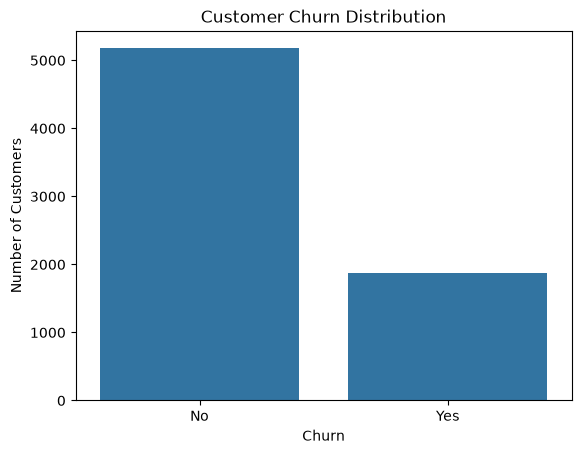

In [10]:
sns.countplot(x="Churn",data=df)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()


In [11]:
df["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

In [12]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

In [13]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [14]:
df=df.dropna(subset=["TotalCharges"])

In [15]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
df=df.drop("customerID",axis=1)

In [17]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


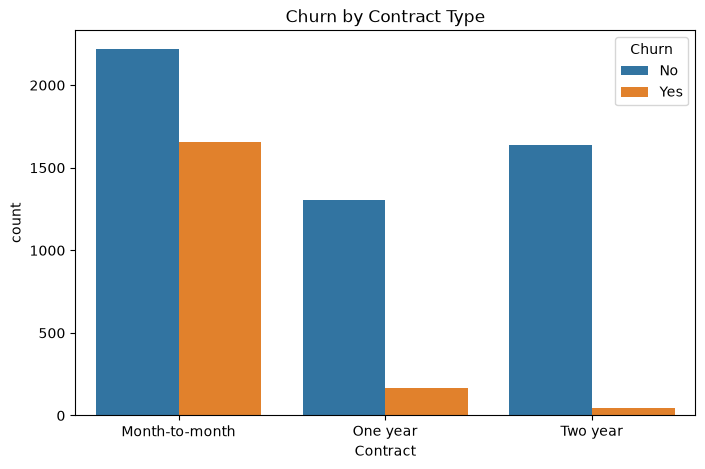

In [18]:
plt.figure(figsize=(8,5))
sns.countplot(
    x="Contract",
    hue="Churn",
    data=df
)
plt.title("Churn by Contract Type")
plt.show()

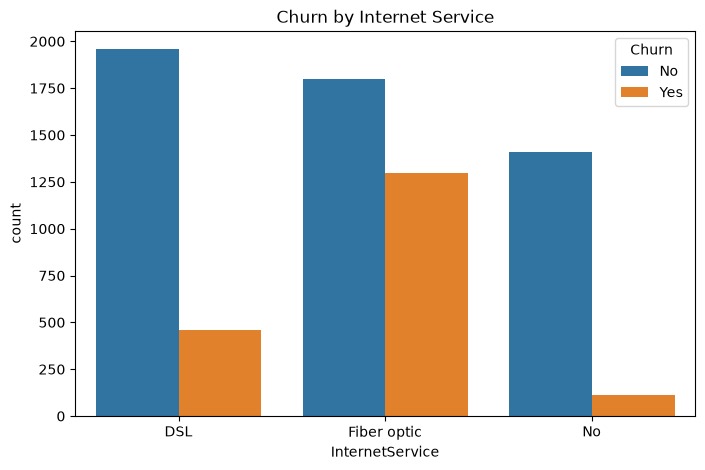

In [19]:
plt.figure(figsize=(8,5))
sns.countplot(
    x="InternetService",
    hue="Churn",
    data=df
)
plt.title("Churn by Internet Service")
plt.show()

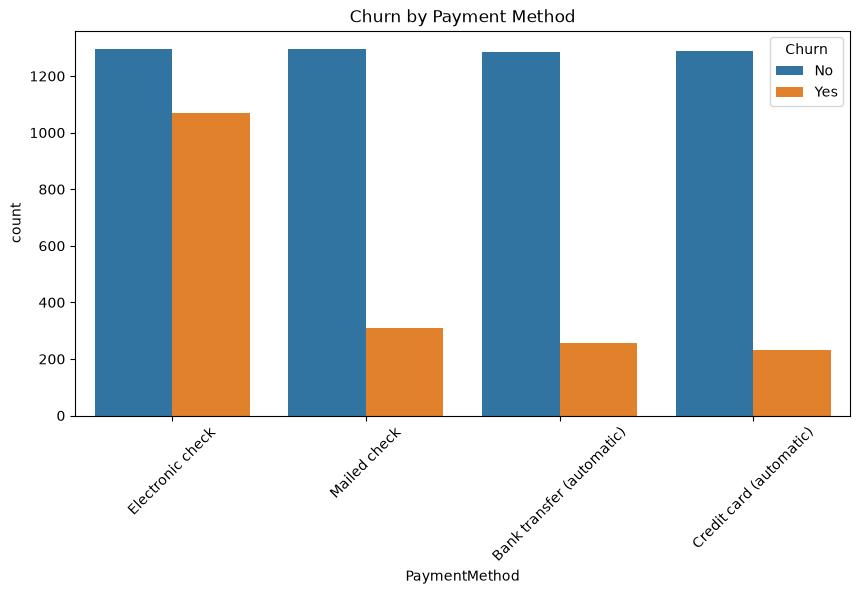

In [20]:
plt.figure(figsize=(10,5))
sns.countplot(
    x="PaymentMethod",
    hue="Churn",
    data=df
)
plt.xticks(rotation=45)
plt.title("Churn by Payment Method")
plt.show()

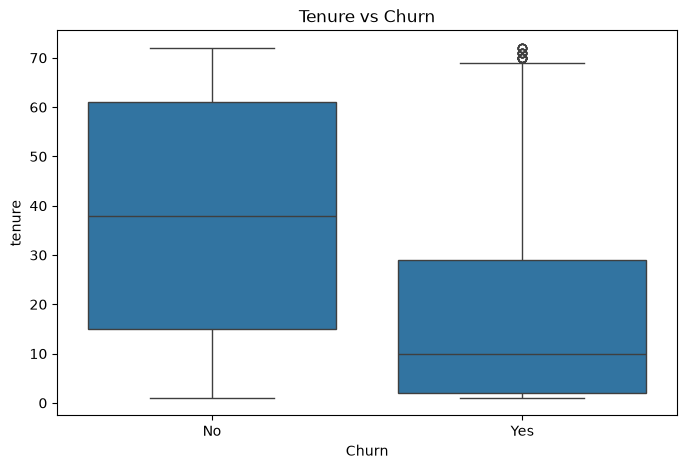

In [21]:
plt.figure(figsize=(8,5))
sns.boxplot(
    x="Churn",
    y="tenure",
    data=df
)
plt.title("Tenure vs Churn")
plt.show()

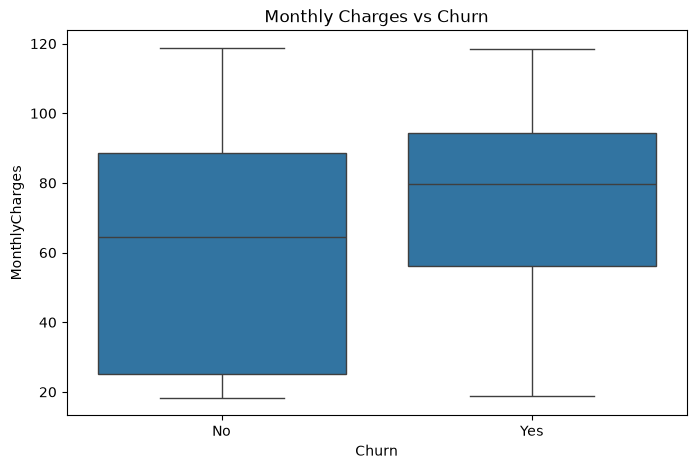

In [22]:
plt.figure(figsize=(8,5))
sns.boxplot(
    x="Churn",
    y="MonthlyCharges",
    data=df
)
plt.title("Monthly Charges vs Churn")
plt.show()

In [23]:
df["Churn"]=df["Churn"].map({"Yes":1,"No":0})

In [24]:
df["Churn"].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

In [25]:
X=df.drop("Churn",axis=1)
y=df["Churn"]
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [26]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [27]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [28]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [29]:
from imblearn.pipeline import Pipeline as ImbPipeline
print( "ImbPipeline imported successfully!")

ImbPipeline imported successfully!


In [30]:
import sys
print(sys.executable)

c:\Users\Lenovo\AppData\Local\Programs\Python\Python314\python.exe


In [31]:
import sys
!{sys.executable} -m pip install imbalanced-learn

In [32]:
from imblearn.pipeline import Pipeline as ImbPipeline
print ("Success!")

Success!


In [33]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [34]:
numeric_features=X.select_dtypes(include=["int64","float64"]).columns
categorical_features=X.select_dtypes(include=["object"]).columns

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_12184\1539227937.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features=X.select_dtypes(include=["object"]).columns


In [35]:
print("Numercial Features:")
print(list(numeric_features))
print("\nCategorical Features:")
print(list(categorical_features))

Numercial Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [36]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [37]:
numeric_transformer=Pipeline(steps=[("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])

In [38]:
categorical_transformer=Pipeline(steps=[("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))])

In [39]:
preprocessor=ColumnTransformer(transformers=[("num",numeric_transformer,numeric_features),("cat",categorical_transformer,categorical_features)])

In [40]:
from imblearn.over_sampling import SMOTE

In [41]:
lr_pipeline=ImbPipeline(steps=[("preprocessor",preprocessor),("smote",SMOTE(random_state=42)),("model",LogisticRegression(max_iter=1000,random_state=42))])

In [42]:
lr_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [43]:
lr_pred=lr_pipeline.predict(X_test)

In [44]:
lr_prob=lr_pipeline.predict_proba(X_test)[:,1]

In [45]:
print("Accuracy:",accuracy_score(y_test,lr_pred))
print("Precision:",precision_score(y_test,lr_pred))
print("Recall:",recall_score(y_test,lr_pred))
print("F1 Score:",f1_score(y_test,lr_pred))
print("ROC-AUC:",roc_auc_score(y_test,lr_prob))

Accuracy: 0.7320540156361052
Precision: 0.49743589743589745
Recall: 0.7780748663101604
F1 Score: 0.6068821689259646
ROC-AUC: 0.8334157301044152


In [46]:
print(classification_report(y_test,lr_pred))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1033
           1       0.50      0.78      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.75      1407



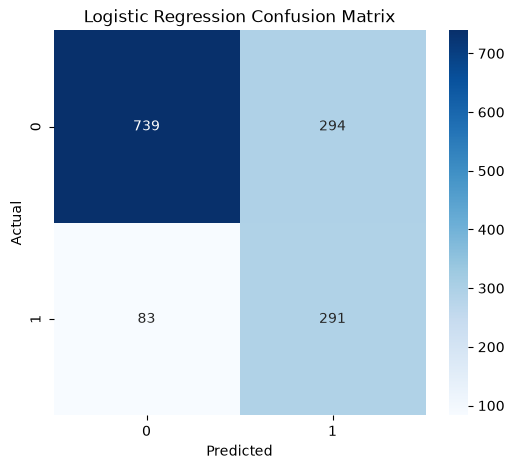

In [47]:
cm=confusion_matrix(y_test,lr_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [48]:
from sklearn.tree import DecisionTreeClassifier

In [49]:
dt_pipeline=ImbPipeline(steps=[("preprocessor",preprocessor),("smote",SMOTE(random_state=42)),("model",DecisionTreeClassifier(max_depth=5,random_state=42))])

In [50]:
dt_pipeline=dt_pipeline.fit(X_train,y_train)

In [52]:
dt_pred=dt_pipeline.predict(X_test)
dt_prob=dt_pipeline.predict_proba(X_test)[:,1]

In [53]:
rf_pipeline=ImbPipeline(steps=[("preprocessor",preprocessor),("smote",SMOTE(random_state=42)),("model",RandomForestClassifier(n_estimators=200,max_depth=10,random_state=42))])

In [54]:
rf_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [55]:
rf_pred=rf_pipeline.predict(X_test)
rf_prob=rf_pipeline.predict_proba(X_test)[:,1]

In [56]:
gb_pipeline=ImbPipeline(steps=[("preprocessor",preprocessor),("smote",SMOTE(random_state=42)),("model",GradientBoostingClassifier(random_state=42))])

In [57]:
gb_pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [58]:
gb_pred=gb_pipeline.predict(X_test)
gb_prob=gb_pipeline.predict_proba(X_test)[:,1]

In [59]:
def evaluate_model(name,y_true,y_pred,y_prob):
    return{"Model":name,"Accuracy":accuracy_score(y_true,y_pred),"Precision":precision_score(y_true,y_pred),"Recall":recall_score(y_true,y_pred),"F1 Score":f1_score(y_true,y_pred),"ROC-AUC":roc_auc_score(y_true,y_prob)}

In [60]:
results=[]
results.append(evaluate_model("Logistic Regression",y_test,lr_pred,lr_prob))
results.append(evaluate_model("Decision Tree",y_test,dt_pred,dt_prob))
results.append(evaluate_model("RandomForest",y_test,rf_pred,rf_prob))
results.append(evaluate_model("Gradient Boosting",y_test,gb_pred,gb_prob))

In [61]:
results_df=pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.732054,0.497436,0.778075,0.606882,0.833416
1,Decision Tree,0.733475,0.499154,0.788770,0.611399,0.811329
2,RandomForest,0.763326,0.543897,0.679144,0.604043,0.826690
3,Gradient Boosting,0.767591,0.550756,0.681818,0.609319,0.834754


In [62]:
lr_fpr,lr_tpr,_=roc_curve(y_test,lr_prob)
dt_fpr,dt_tpr,_=roc_curve(y_test,dt_prob)
rf_fpr,rf_tpr,_=roc_curve(y_test,rf_prob)
gb_fpr,gb_tpr,_=roc_curve(y_test,gb_prob)

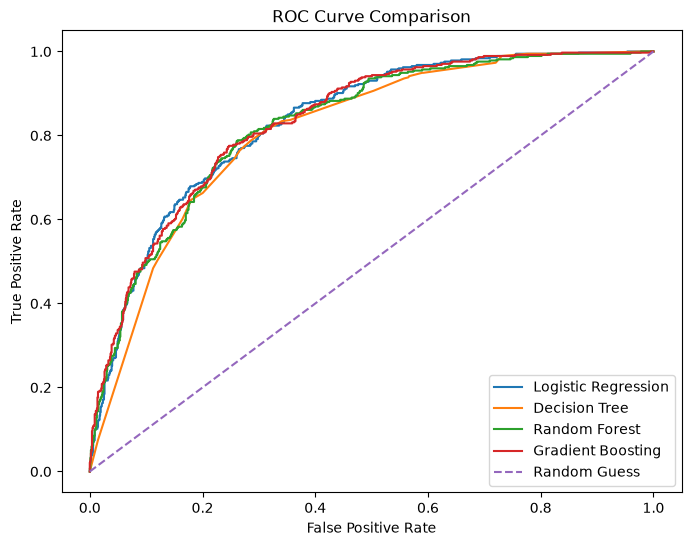

In [63]:
plt.figure(figsize=(8,6))
plt.plot( lr_fpr,lr_tpr,label="Logistic Regression")
plt.plot(dt_fpr,dt_tpr,label="Decision Tree")
plt.plot(rf_fpr,rf_tpr,label="Random Forest")
plt.plot(gb_fpr,gb_tpr,label="Gradient Boosting")
plt.plot([0,1],[0,1],linestyle="--",label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


In [64]:
from sklearn.model_selection import GridSearchCV

In [65]:
param_grid={"model__n_estimators":[100,200],"model__max_depth":[None,10,20],"model__min_samples_split":[2,5],"model__min_samples_leaf":[1,2]}

In [66]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [67]:
rf_pipeline=ImbPipeline([('Scaler',StandardScaler()),('classifer',RandomForestClassifier(random_state=42))])

In [80]:
grid_search=GridSearchCV(estimator=rf_pipeline,param_grid=param_grid,cv=5,scoring="roc_auc",n_jobs=-1)

In [82]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
rf_pipeline=Pipeline([('scaler',StandardScaler()),('classifier',RandomForestClassifier(random_state=42))])
print(rf_pipeline.named_steps.keys())

dict_keys(['scaler', 'classifier'])


In [81]:
grid_search.fit(X_train,y_train)

ValueError: Invalid parameter 'model' for estimator Pipeline(steps=[('Scaler', StandardScaler()),
                ('classifer', RandomForestClassifier(random_state=42))]). Valid parameters are: ['memory', 'steps', 'transform_input', 'verbose'].

In [83]:
param_grid={'classifier__n_estimators':[100,200],'classifier__max_depth':[None,10,20],'classifier__min_samples_split':[2,5],"classifier__min_samples_leaf":[1,2]}

In [85]:
from sklearn.model_selection import GridSearchCV
grid_search=GridSearchCV(estimator=rf_pipeline,param_grid=param_grid,cv=5,scoring="roc_auc",n_jobs=-1,verbose=1)

In [86]:
print(X_train.shape)
print(y_train.shape)

(5634, 20)
(5634,)


In [87]:
from sklearn.model_selection import train_test_split
X=df.drop('Churn',axis=1)
y=df['Churn']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [89]:
print(df.columns.tolist())
print(df.dtypes)

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [90]:
df = df.drop(columns=["customerID"], errors="ignore")

# Convert TotalCharges to numeric if it contains blank strings
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

# Fill missing numerical values with their median
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"Yes": 1, "No": 0})

print(X.shape)
print(y.value_counts(dropna=False))

(7043, 19)
Churn
0    5174
1    1869
Name: count, dtype: int64


In [91]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

In [92]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [93]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

In [94]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best CV Accuracy: 0.804224352147675


In [95]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = grid_search.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Test Accuracy: 0.808374733853797
              precision    recall  f1-score   support

           0       0.84      0.91      0.88      1035
           1       0.68      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



In [69]:
from sklearn.model_selection import train_test_split

In [70]:
df=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [76]:
X=df.drop('Churn',axis=1)
y=df['Churn']

In [77]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [96]:
grid_search.best_params_

{'classifier__max_depth': 10,
 'classifier__min_samples_leaf': 2,
 'classifier__min_samples_split': 2,
 'classifier__n_estimators': 100}

In [97]:
grid_search.best_score_

np.float64(0.804224352147675)

In [98]:
best_model=grid_search.best_estimator_

In [99]:
final_pred=best_model.predict(X_test)
final_prob=best_model.predict_proba(X_test)[:,1]

In [100]:
print("Accuracy:",accuracy_score(y_test,final_pred))
print("Precision",precision_score(y_test,final_pred))
print("Recall",recall_score(y_test,final_pred))
print("F1 Score",f1_score(y_test,final_pred))
print("ROC-AUC",roc_auc_score(y_test,final_prob))

Accuracy: 0.808374733853797
Precision 0.6843971631205674
Recall 0.516042780748663
F1 Score 0.5884146341463414
ROC-AUC 0.8393061045234959


In [101]:
print(classification_report(y_test,final_pred))

              precision    recall  f1-score   support

           0       0.84      0.91      0.88      1035
           1       0.68      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



In [102]:
final_preprocessor=(best_model.named_steps["preprocessor"])

In [103]:
feature_names=(final_preprocessor.get_feature_names_out())

In [105]:
importances=(best_model.named_steps["classifier"].feature_importances_)

In [106]:
feature_importance=pd.DataFrame({"Feature":feature_names,"Importance":importances})

In [107]:
feature_importance=(feature_importance.sort_values(by="Importance",ascending=False))

In [108]:
feature_importance.head(15)

,Feature,Importance
1,num__tenure,0.152082
3,num__TotalCharges,0.117795
36,cat__Contract_Month-to-month,0.087466
2,num__MonthlyCharges,0.076293
16,cat__InternetService_Fiber optic,0.056260
18,cat__OnlineSecurity_No,0.055661
43,cat__PaymentMethod_Electronic check,0.045393
27,cat__TechSupport_No,0.043858
38,cat__Contract_Two year,0.031420
21,cat__OnlineBackup_No,0.019592


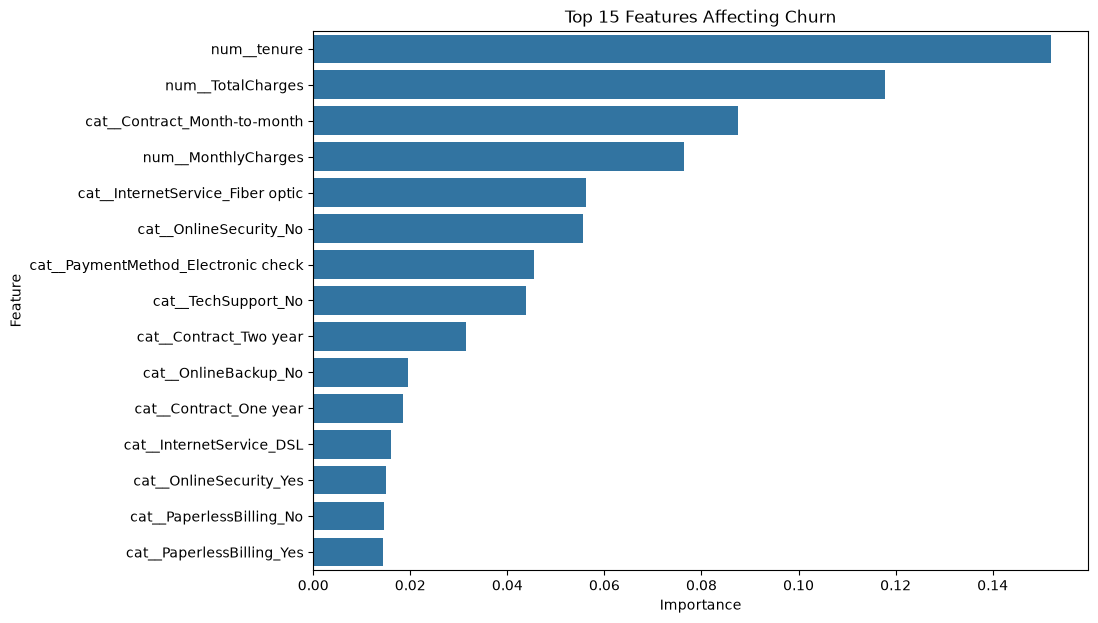

In [109]:
plt.figure(figsize=(10,7))
sns.barplot(data=feature_importance.head(15),x="Importance",y="Feature")
plt.title("Top 15 Features Affecting Churn")
plt.show()

In [110]:
test_probabilities=(best_model.predict_proba(X_test)[:,1])

In [111]:
risk_df=X_test.copy()
risk_df["Churn_Probability"]=(test_probabilities)

In [112]:
def churn_risk(probability):
     if probability<0.30:
          return "Low Risk"
     elif probability<0.60:
          return "Medium Risk"
     else:
          return "High Risk"

In [113]:
risk_df["Risk_Level"]=(risk_df["Churn_Probability"].apply(churn_risk))

In [114]:
risk_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn_Probability,Risk_Level
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0.013926,Low Risk
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0.671831,High Risk
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0.061172,Low Risk
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0.310081,Medium Risk
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0.013597,Low Risk


In [115]:
high_risk_customers=(risk_df[risk_df["Risk_Level"]=="High Risk"])

In [116]:
high_risk_customers=(high_risk_customers.sort_values("Churn_Probability",ascending=False))

In [117]:
high_risk_customers.head(20)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn_Probability,Risk_Level
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,0.896581,High Risk
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,0.888576,High Risk
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,0.882211,High Risk
6623,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,76.45,76.45,0.860503,High Risk
3727,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,0.858637,High Risk
6190,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Yes,Month-to-month,No,Electronic check,80.50,80.50,0.855171,High Risk
6748,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Yes,Month-to-month,Yes,Electronic check,85.00,85.00,0.851448,High Risk
3346,Female,1,No,No,2,Yes,Yes,Fiber optic,No,No,...,No,No,Yes,Month-to-month,Yes,Electronic check,84.05,186.05,0.850926,High Risk
2729,Female,0,No,No,2,Yes,Yes,Fiber optic,No,No,...,No,No,Yes,Month-to-month,Yes,Electronic check,85.70,169.80,0.846424,High Risk
2753,Female,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Yes,Yes,Month-to-month,No,Mailed check,95.65,95.65,0.846348,High Risk


In [1]:
import pandas as pd
import joblib

model = joblib.load(
    "customer_churn_pipeline.pkl"
)

customer = pd.DataFrame({
    "gender": ["Male"],
    "SeniorCitizen": [0],
    "Partner": ["Yes"],
    "Dependents": ["No"],
    "tenure": [5],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": [
        "Electronic check"
    ],
    "MonthlyCharges": [90.0],
    "TotalCharges": [450.0]
})

prediction = model.predict(customer)[0]

probability = model.predict_proba(
    customer
)[0][1]

print(
    "Churn Probability:",
    round(probability * 100, 2),
    "%"
)

if prediction == 1:
    print("Prediction: Customer will likely churn")
else:
    print("Prediction: Customer is likely to stay")

Churn Probability: 73.0 %
Prediction: Customer is likely to stay


In [2]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.
